# Evaluación Forense de Modelos, Optimización de Umbrales y Comparativa Global de Predicción

**Resumen ejecutivo**

- **Objetivo.** Evaluar con rigor forense (Fase 5 de CRISP-DM) **qué modelos funcionan realmente en nuestro proyecto, cuáles fallan ante clases desbalanceadas y cuál realiza mejor la predicción** sobre escenarios reales de vivienda joven (18–34 años) en el Reino Unido.
- **Cobertura técnica:**
  1. **Trampa del *accuracy* y Modelo Ingenuo:** contraste sobre dos objetivos desbalanceados reales —*Esfuerzo Crítico* ($\ge 0,80$, `18,3 %` positivos en el cuadro maestro) y *Oferta Hipotecaria de Tasa Atípica IQR* (`9,77 %` positivos en F2, $n=7.796$).
  2. **Matriz de confusión orientada con costos asimétricos + verificación manual con `assert`:** cálculo sin librerías de Precisión, Recall y **F1 armónica vs. media aritmética**, junto con `classification_report` completo (`macro avg` vs. `weighted avg`).
  3. **Validación cruzada estratificada `k=5` dentro de `Pipeline`:** estabilidad pliegue por pliegue (`media ± desviación estándar`) sin fuga del escalador.
  4. **Curvas ROC-AUC, Precisión–Recall y Optimización del Umbral de Decisión (`predict_proba`):** diseño de **3 umbrales operativos** según costo de error (*Alerta temprana*, *Equilibrado F1*, *Alta precisión para subsidios*).
  5. **Panel Comparativo Global y Simulador Lado a Lado por Región Real:** prueba directa de Árbol CART, Random Forest, KNN (`k=5` y `k=15`), Naive Bayes y Modelo Ingenuo sobre las 10 regiones británicas.
- **Módulo espejo en terminal:** `script/proyecto/evaluacion_modelos.py`.

---
### Ficha Taxonómica de Evaluación (Fase 5 de CRISP-DM: Comparativa Global Con y Sin Etiqueta)
- **Qué integra este cuaderno:** compara en igualdad de condiciones **todas las predicciones CON Etiqueta (Tipo 1 Regresión y Tipo 2 Clasificación)** y **los modelos SIN Etiqueta (Tipo 3 Clustering y Tipo 4 Asociación)**, midiendo la **cantidad exacta de aciertos (`TP, TN, FP, FN`)** bajo escenarios balanceados (`50/50`) y desbalanceados (`18,3 %` y `9,77 %`).
- **Hallazgo clave de aciertos por umbral en tasas hipotecarias atípicas F2 (`190` casos positivos reales en `n_test = 1.949`):**
  - **Modelo Ingenuo (*Dummy*):** `90,25 %` de accuracy engañoso con **`0/190` atípicas detectadas (`0,0 %` recall)**.
  - **Árbol CART (`d=4`) en umbral por defecto `0,50`:** detecta `59/190` (`31,1 %` recall, **`100 %` precisión, `0` falsas alarmas**).
  - **Árbol CART (`d=4`) en umbral `0,40` (`alta_precision`):** detecta `59/190` con **`0` falsas alarmas (`100 %` precisión)**.
  - **Árbol CART (`d=4`) en umbral `0,30` (`equilibrado_f1`):** detecta **`188/190` atípicas (`99,0 %` recall, F1=`0,619`, Youden $J=0,859$)**.
  - **Árbol CART (`d=4`) en umbral `0,05` (`alerta_temprana`):** detecta **`190/190` atípicas (`100,0 %` recall)**.
  - **KNN escalado (`k=5`):** detecta **`158/190` atípicas (`83,2 %` recall, `81,9 %` precisión, F1=`0,825`)**.
---


## 0. Entorno, raíz del proyecto y módulos

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto.evaluacion_modelos import (
    barrido_umbrales_decision,
    enriquecer_contrato_json,
    evaluar_escenario_completo,
    fig_barrido_umbral_costos,
    fig_curvas_roc_pr,
    fig_cv5_pliegues,
    fig_ingenuo_vs_modelos,
    fig_ranking_global_prediccion,
    preparar_escenarios,
    simular_predicciones_por_region,
    tabla_semaforo_global,
    verificar_metricas_manuales,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
print("Raiz del proyecto:", PROYECTO.name, "| Semilla:", config.SEED)

Raiz del proyecto: mineria (3) | Semilla: 42


## 1. La Trampa del *Accuracy*: Modelo Ingenuo vs. Modelos Reales en Clases Desbalanceadas

Cuando la categoría de interés es minoritaria (por ejemplo, el **9,77 %** de hipotecas con tasa atípica en F2 o el **18,3 %** de observaciones con esfuerzo crítico $\ge 0,80$), predecir siempre la categoría mayoritaria produce un *accuracy* engañosamente alto (**90,2 %** y **81,7 %**) mientras captura **0 % de los casos críticos (`Recall = 0,000`)**.

Por ello descomponemos la predicción en la **matriz de confusión** (filas = realidad, columnas = predicción) y evaluamos las tres métricas clave:

$$\text{Precisión} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

La **media armónica ($F_1$)** castiga severamente el desbalance entre Precisión y Recall (siempre se acerca al menor de los dos), impidiendo maquillar un Recall colapsado como sí ocurriría con la media aritmética.

ESCENARIO A · Cuadro Maestro: Esfuerzo Critico >= 0,80 (18,3 % positivos):

ESCENARIO B · Catalogo Hipotecario F2: Tasa Atipica IQR (9,77 % positivos, n=7.796):


,modelo,acc_test,precision_pos,recall_pos,f1_pos,roc_auc,pr_auc,cv5_f1_media,cv5_f1_desv,TP,FP,FN
0,Ingenuo (mayoritaria),0.8333,0.0000,0.0000,0.0000,0.5000,0.1667,0.0000,0.0000,0,0,3
1,Arbol CART (d=4),0.7778,0.3333,0.3333,0.3333,0.6000,0.2222,0.6743,0.1966,1,2,2
2,Naive Bayes (GaussianNB),0.7778,0.0000,0.0000,0.0000,0.7111,0.3833,0.2333,0.2906,0,1,3
3,KNN escalado (k=5),0.8889,1.0000,0.3333,0.5000,1.0000,1.0000,0.6000,0.3266,1,0,2
4,KNN escalado (k=15),0.8333,0.0000,0.0000,0.0000,0.9778,0.8333,0.0000,0.0000,0,0,3
5,Random Forest (ensamble),0.8889,1.0000,0.3333,0.5000,0.9778,0.9167,0.6133,0.2115,1,0,2


,modelo,acc_test,precision_pos,recall_pos,f1_pos,roc_auc,pr_auc,cv5_f1_media,cv5_f1_desv,TP,FP,FN
0,Ingenuo (mayoritaria),0.9025,0.0000,0.0000,0.0000,0.5000,0.0975,0.0000,0.0000,0,0,190
1,Arbol CART (d=4),0.9328,1.0000,0.3105,0.4739,0.9547,0.6452,0.4310,0.0338,59,0,131
2,Naive Bayes (GaussianNB),0.3602,0.1322,1.0000,0.2336,0.6661,0.1833,0.2267,0.0067,190,1247,0
3,KNN escalado (k=5),0.9656,0.8187,0.8316,0.8251,0.9736,0.8481,0.7748,0.0287,158,35,32
4,KNN escalado (k=15),0.9466,0.7500,0.6789,0.7127,0.9793,0.7951,0.7183,0.0117,129,43,61
5,Random Forest (ensamble),0.9369,1.0000,0.3526,0.5214,0.9747,0.8213,0.4906,0.0301,67,0,123


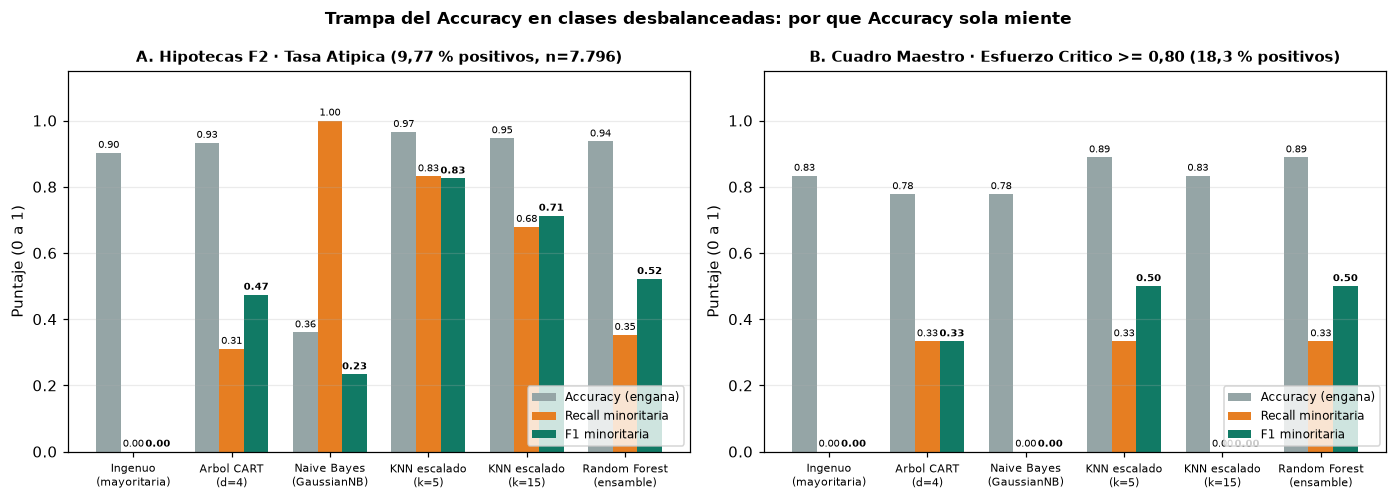

In [2]:
escenarios = preparar_escenarios()
ev_bal = evaluar_escenario_completo(escenarios["maestro_balanceado"], "maestro_balanceado")
ev_crit = evaluar_escenario_completo(escenarios["maestro_critico"], "maestro_critico")
ev_hip = evaluar_escenario_completo(escenarios["hipotecas_atipico"], "hipotecas_atipico")

cols_ver = ["modelo", "acc_test", "precision_pos", "recall_pos", "f1_pos", "roc_auc", "pr_auc", "cv5_f1_media", "cv5_f1_desv", "TP", "FP", "FN"]
print("ESCENARIO A · Cuadro Maestro: Esfuerzo Critico >= 0,80 (18,3 % positivos):")
display(ev_crit["tabla"][cols_ver])

print("\nESCENARIO B · Catalogo Hipotecario F2: Tasa Atipica IQR (9,77 % positivos, n=7.796):")
display(ev_hip["tabla"][cols_ver])

fig1 = fig_ingenuo_vs_modelos(ev_hip, ev_crit)
plt.show()

## 2. Matriz de Confusión Forense, `classification_report` y Verificación Manual (`assert`)

Asignamos costo real a cada celda en el contexto de protección al comprador joven:
- **TP (Verdadero Positivo):** oferta abusiva o región crítica detectada a tiempo → joven advertido / protegido.
- **FN (Falso Negativo):** oferta atípica o zona crítica marcada como "normal" → riesgo grave de sobreendeudamiento.
- **FP (Falso Positivo):** oferta normal marcada en alerta → costo menor si es aviso informativo, pero alto si dispara un subsidio limitado.
- **TN (Verdadero Negativo):** caso normal descartado correctamente.

In [3]:
for nombre in ("Arbol CART (d=4)", "KNN escalado (k=5)", "KNN escalado (k=15)", "Random Forest (ensamble)"):
    y_te = ev_hip["y_test"].to_numpy()
    y_pr = ev_hip["modelos_fit"][nombre].predict(ev_hip["X_test"])
    verif = verificar_metricas_manuales(y_te, y_pr)
    print(f"=== {nombre} (F2 atipico, n_test={len(y_te)}) ===")
    print(f"Matriz [TN={verif['TN']}, FP={verif['FP']} | FN={verif['FN']}, TP={verif['TP']}]")
    print(f"Verificacion manual (assert == sklearn OK): P={verif['precision_manual']:.4f} | "
          f"R={verif['recall_manual']:.4f} | F1 armonica={verif['f1_armonica']:.4f} "
          f"vs. Media aritmetica={verif['media_aritmetica']:.4f} (penalizacion={verif['penalizacion_armonica']:+.4f})")
    print(ev_hip["reportes"][nombre])

=== Arbol CART (d=4) (F2 atipico, n_test=1949) ===
Matriz [TN=1759, FP=0 | FN=131, TP=59]
Verificacion manual (assert == sklearn OK): P=1.0000 | R=0.3105 | F1 armonica=0.4739 vs. Media aritmetica=0.6553 (penalizacion=+0.1814)
                precision    recall  f1-score   support

No critico (0)       0.93      1.00      0.96      1759
  Positivo (1)       1.00      0.31      0.47       190

      accuracy                           0.93      1949
     macro avg       0.97      0.66      0.72      1949
  weighted avg       0.94      0.93      0.92      1949

=== KNN escalado (k=5) (F2 atipico, n_test=1949) ===
Matriz [TN=1724, FP=35 | FN=32, TP=158]
Verificacion manual (assert == sklearn OK): P=0.8187 | R=0.8316 | F1 armonica=0.8251 vs. Media aritmetica=0.8251 (penalizacion=+0.0001)
                precision    recall  f1-score   support

No critico (0)       0.98      0.98      0.98      1759
  Positivo (1)       0.82      0.83      0.83       190

      accuracy                      

## 3. Validación Cruzada Estratificada `k=5` en `Pipeline` y Curvas ROC / Precisión–Recall

Un único split puede ser afortunado o desfavorable; `StratifiedKFold(5)` dentro de `Pipeline(StandardScaler(), ...)` ajusta el escalador **estrictamente dentro de los 4/5 de entrenamiento de cada pliegue** y reporta `media ± desviación estándar`.

accuracy              f1  ...  recall roc_auc        
                             mean     std    mean  ...     std    mean     std
modelo                                             ...                        
Arbol CART (d=4)           0.9284  0.0030  0.4310  ...  0.0310  0.9502  0.0049
Ingenuo (mayoritaria)      0.9023  0.0003  0.0000  ...  0.0000  0.5000  0.0000
KNN escalado (k=15)        0.9447  0.0022  0.7183  ...  0.0277  0.9764  0.0025
KNN escalado (k=5)         0.9544  0.0059  0.7747  ...  0.0563  0.9731  0.0107
Naive Bayes (GaussianNB)   0.3436  0.0120  0.2267  ...  0.0353  0.6754  0.0317
Random Forest (ensamble)   0.9316  0.0022  0.4907  ...  0.0388  0.9739  0.0022

[6 rows x 8 columns]

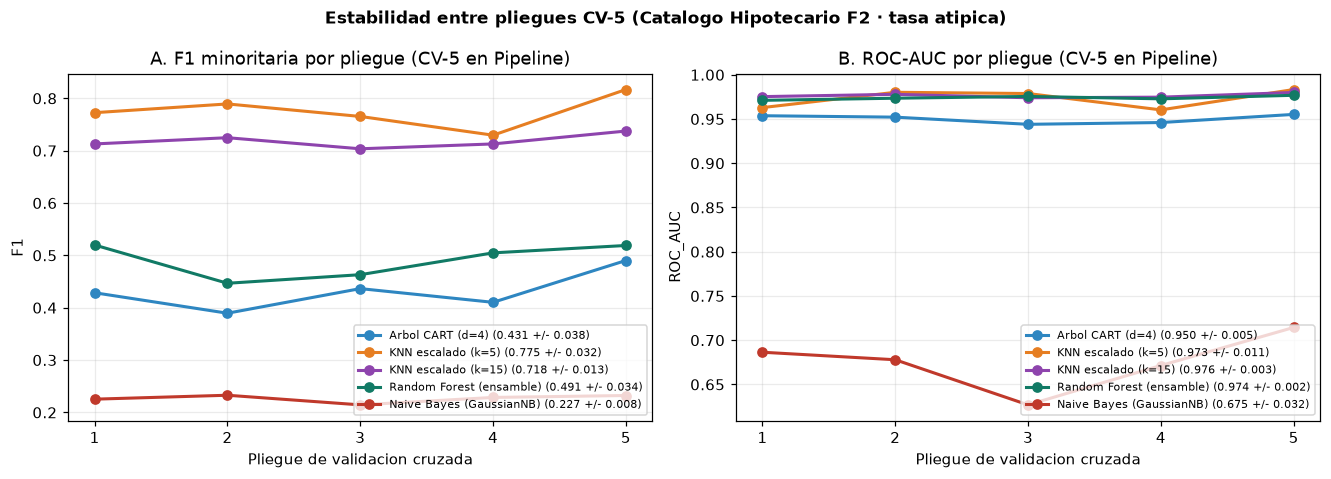

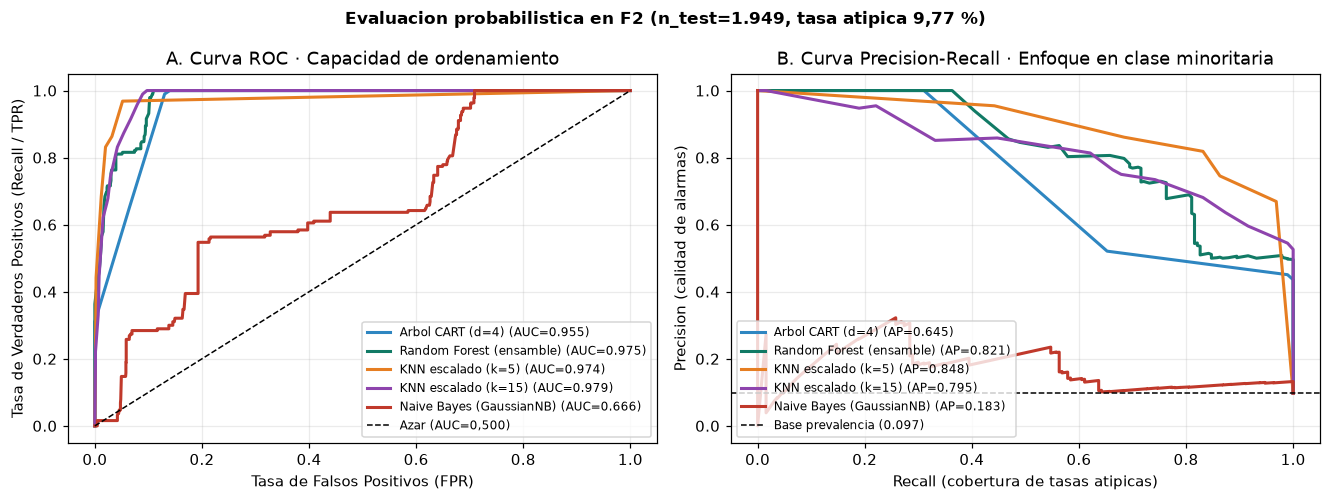

In [4]:
resumen_cv = (
    ev_hip["cv_pliegues"]
    .groupby("modelo")[["accuracy", "f1", "recall", "roc_auc"]]
    .agg(["mean", "std"])
    .round(4)
)
display(resumen_cv)

fig2 = fig_cv5_pliegues(ev_hip["cv_pliegues"])
plt.show()
fig3 = fig_curvas_roc_pr(ev_hip)
plt.show()

## 4. Optimización del Umbral de Decisión (`predict_proba`) ante Costos Asimétricos

Mover el umbral de decisión $\tau$ sobre `predict_proba` adapta el **mismo modelo ganador (Árbol CART `d=4`)** a tres necesidades distintas de política pública y producto digital:
1. **Alerta informativa temprana (FP barato, FN caro):** bajar $\tau$ maximiza **Recall** para atrapar la mayoría de ofertas abusivas.
2. **Equilibrio operativo (tablero principal):** elegir $\tau$ que maximiza **F1 armónica**.
3. **Asignación de subsidios limitados (FP caro):** subir $\tau$ maximiza **Precisión** para que casi toda intervención sea certera.

Tres perfiles de umbral recomendados para el contrato de prediccion:


,umbral,TP_detectados,FN_perdidos,FP_falsas_alarmas,TN_correctos,precision,recall,f1,media_aritmetica,fpr,youden_J,total_alarmas
0,0.05,190,0,246,1513,0.4358,1.0000,0.6070,0.7179,0.1399,0.8601,436
1,0.10,190,0,246,1513,0.4358,1.0000,0.6070,0.7179,0.1399,0.8601,436
2,0.15,190,0,246,1513,0.4358,1.0000,0.6070,0.7179,0.1399,0.8601,436
3,0.20,190,0,246,1513,0.4358,1.0000,0.6070,0.7179,0.1399,0.8601,436
4,0.25,190,0,246,1513,0.4358,1.0000,0.6070,0.7179,0.1399,0.8601,436
5,0.30,188,2,229,1530,0.4508,0.9895,0.6194,0.7202,0.1302,0.8593,417
6,0.40,59,131,0,1759,1.0000,0.3105,0.4739,0.6553,0.0000,0.3105,59
7,0.50,59,131,0,1759,1.0000,0.3105,0.4739,0.6553,0.0000,0.3105,59
8,0.60,59,131,0,1759,1.0000,0.3105,0.4739,0.6553,0.0000,0.3105,59
9,0.70,59,131,0,1759,1.0000,0.3105,0.4739,0.6553,0.0000,0.3105,59


,umbral,uso,precision,recall,f1,TP,FP
alerta_temprana,0.05,Alerta informativa web de bajo costo (prioriza...,0.4358,1.0,0.607,190,246
equilibrado_f1,0.3,Operacion general y tablero ejecutivo (maximiz...,0.4508,0.9895,0.6194,188,229
alta_precision,0.4,Asignacion de subsidios o revisiones costosas ...,1.0,0.3105,0.4739,59,0


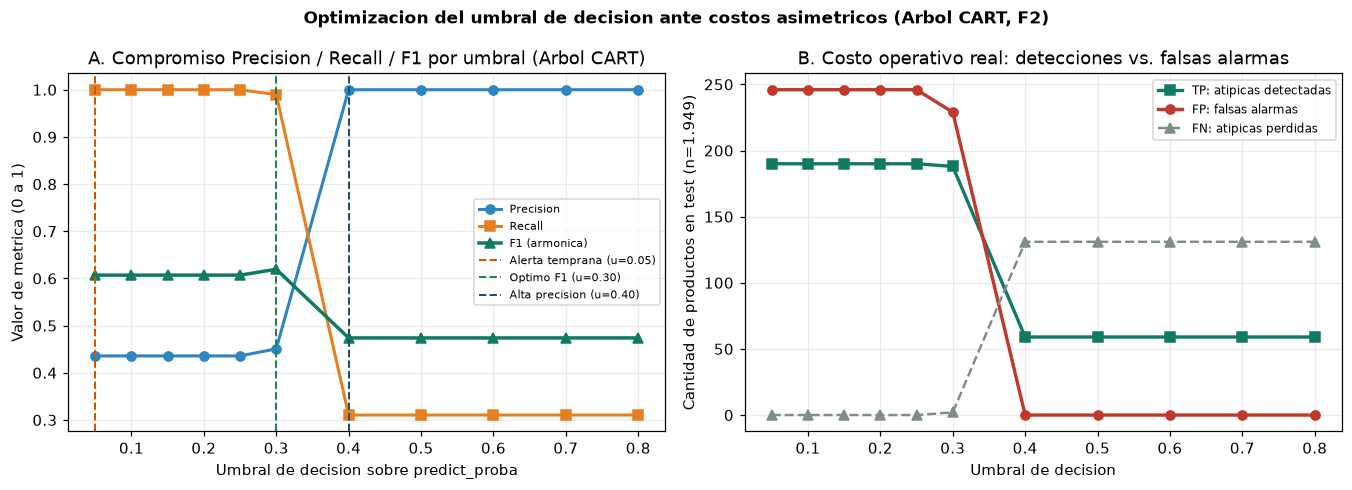

In [5]:
df_umb, perfiles_u = barrido_umbrales_decision(
    ev_hip["y_test"].to_numpy(), ev_hip["probs"]["Arbol CART (d=4)"]
)
display(df_umb)

print("Tres perfiles de umbral recomendados para el contrato de prediccion:")
display(pd.DataFrame(perfiles_u).T)

fig4 = fig_barrido_umbral_costos(df_umb, perfiles_u)
plt.show()

## 5. Comparativa Global Definitiva: ¿Qué Modelos Nos Funcionan, Cuáles Fallan y Cuál Predice Mejor?

Esta sección consolida **todos los modelos del proyecto** en una tabla semáforo única y ejecuta un **simulador de predicción lado a lado** sobre el perfil real mediano de las **10 regiones del Reino Unido**, comparando el veredicto de cada algoritmo contra la realidad observada.

1) Simulador de prediccion lado a lado sobre perfiles REALES de las 10 regiones del UK:

2) Panel Semaforo Global — Que algoritmos funcionan mejor en nuestro proyecto:

Contrato enriquecido con 3 umbrales operativos y perfiles regionales: data\modelos\contrato_prediccion.json


,region,esfuerzo_mediano_real,real,Arbol_d4,NaiveBayes,KNN_k5,KNN_k15,RandomForest
0,London,1.018,Alto,Alto (1.00) [OK],Alto (0.63) [OK],Alto (1.00) [OK],Alto (0.67) [OK],Alto (0.90) [OK]
1,South East,0.835,Alto,Alto (1.00) [OK],Alto (0.91) [OK],Alto (1.00) [OK],Alto (0.73) [OK],Alto (0.90) [OK]
2,East of England,0.774,Alto,Alto (1.00) [OK],Alto (0.67) [OK],Alto (1.00) [OK],Alto (0.67) [OK],Alto (0.86) [OK]
3,South West,0.726,Alto,Alto (1.00) [OK],Alto (0.64) [OK],Alto (1.00) [OK],Alto (0.67) [OK],Alto (0.96) [OK]
4,West Midlands,0.569,Alto,Moderado (0.00) [ERR],Moderado (0.31) [ERR],Moderado (0.40) [ERR],Moderado (0.40) [ERR],Moderado (0.33) [ERR]
5,East Midlands,0.558,Moderado,Moderado (0.00) [OK],Moderado (0.39) [OK],Moderado (0.40) [OK],Alto (0.53) [ERR],Moderado (0.31) [OK]
6,Yorkshire and The Humber,0.491,Moderado,Moderado (0.00) [OK],Moderado (0.31) [OK],Moderado (0.00) [OK],Moderado (0.40) [OK],Moderado (0.17) [OK]
7,Wales,0.479,Moderado,Moderado (0.00) [OK],Moderado (0.03) [OK],Moderado (0.00) [OK],Moderado (0.13) [OK],Moderado (0.06) [OK]
8,North West,0.473,Moderado,Moderado (0.00) [OK],Moderado (0.23) [OK],Moderado (0.00) [OK],Moderado (0.33) [OK],Moderado (0.05) [OK]
9,North East,0.437,Moderado,Moderado (0.00) [OK],Moderado (0.02) [OK],Moderado (0.00) [OK],Moderado (0.13) [OK],Moderado (0.07) [OK]


,Algoritmo / Familia,Estado,Maestro 50/50 (F1 / CV-5),Critico 18% (F1 / AUC),"Hipotecas Atipico 9,8% (F1 / AUC)",Peso / Latencia F2,Veredicto practico
0,Arbol de Decision CART (max_depth=4),GANADOR PRINCIPAL,0.941 / 0.783,0.333 / 0.600,0.474 / 0.955,1.6 KB / 0.9 ms,"Mejor balance global: explicable con reglas, l..."
1,Random Forest (ensamble 200 arboles),MEJOR ENSAMBLE (CHALLENGER),0.889 / 0.867,0.500 / 0.978,0.521 / 0.975,231.2 KB / 20.7 ms,Maxima robustez en desbalance y probabilidades...
2,"KNN escalado (k=5, Pipeline)",CHALLENGER LOCAL,0.941 / 0.900,0.500 / 1.000,0.825 / 0.974,83.0 KB / 15.6 ms,"Excelente precision local, pero lento en predi..."
3,"KNN escalado (k=15, Pipeline)",ESTABLE / SUBAJUSTE EN MINORITARIA,0.947 / 0.850,0.000 / 0.978,0.713 / 0.979,83.0 KB / 22.0 ms,"Suaviza fronteras, pero con 9,8 % de positivos..."
4,Naive Bayes (GaussianNB),DESCARTADO (SOLO BASELINE),0.500 / 0.800,0.000 / 0.711,0.234 / 0.666,0.9 KB / 0.6 ms,"Muy veloz, pero viola normalidad e independenc..."
5,Modelo Ingenuo (clase mayoritaria),CONTROL NEGATIVO (NO USAR),0.000 / 0.500,0.000 / 0.500,0.000 / 0.500,0.6 KB / 0.0 ms,"Exhibe 90,2 % accuracy en F2 detectando 0 % de..."
6,Clustering (K-Means + Ward + MiniBatchKMeans 1M),ACTIVO (NO SUPERVISADO),"Enriquece CART CV-5: 0,783 -> 0,800","Separa 100 % London/SE (esf. 0,90)","F2 silueta 0,464 · 1M F1 en 45,8 MB",Streaming O(1) RAM (local/cloud),"Ideal para segmentar mercados, hipotecas y 1M+..."
7,Reglas de Asociacion (Apriori puro),ACTIVO (PATRONES),195 reglas F1 / 481 reglas F2,"Detached+Freehold -> Extremo (lift 2,00)","Discounted -> Tasa Baja Q1 (lift 3,96)","23,6 MB RAM · auditable",Ideal para alertas de combinaciones de riesgo ...


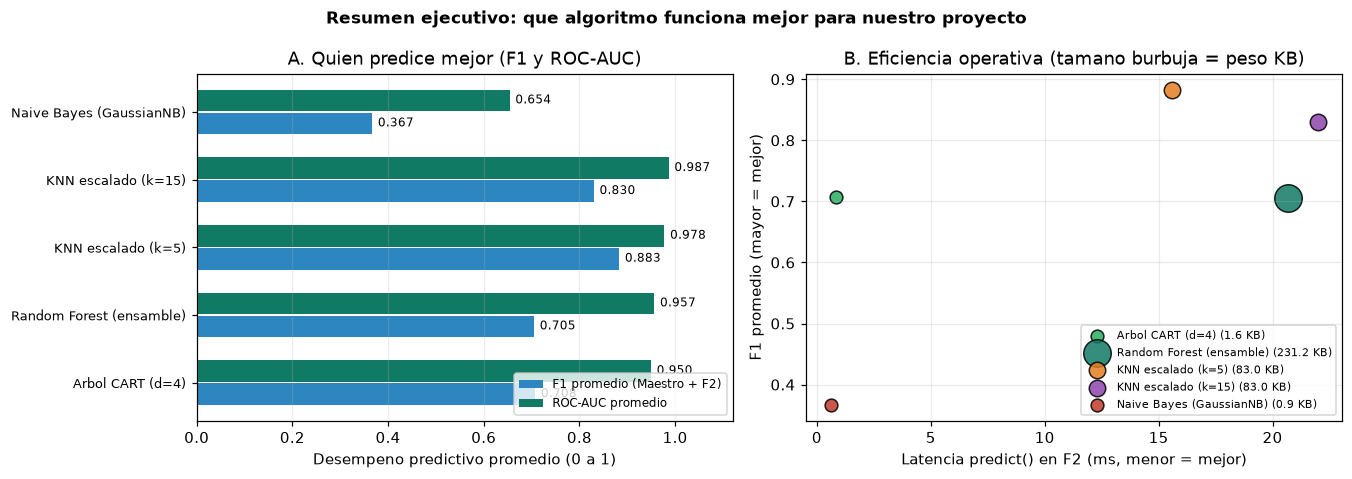

In [6]:
sim_reg, perfiles_reg = simular_predicciones_por_region(escenarios["maestro_balanceado"])
print("1) Simulador de prediccion lado a lado sobre perfiles REALES de las 10 regiones del UK:")
display(sim_reg)

semaforo = tabla_semaforo_global(ev_bal, ev_crit, ev_hip)
print("\n2) Panel Semaforo Global — Que algoritmos funcionan mejor en nuestro proyecto:")
display(semaforo)

fig5 = fig_ranking_global_prediccion(ev_bal, ev_hip)
plt.show()

# Exportar artefactos livianos y enriquecer contrato JSON
df_umb.to_csv(config.RUTA_EVALUACION_UMBRALES, index=False)
cv_all = pd.concat([ev_bal["cv_pliegues"], ev_crit["cv_pliegues"], ev_hip["cv_pliegues"]], ignore_index=True)
cv_all.to_csv(config.RUTA_EVALUACION_CV5, index=False)
semaforo.to_csv(config.RUTA_COMPARATIVA_GLOBAL, index=False)
ruta_json = enriquecer_contrato_json(perfiles_u, perfiles_reg, semaforo)
print(f"\nContrato enriquecido con 3 umbrales operativos y perfiles regionales: {ruta_json.relative_to(config.PROYECTO)}")

### Veredicto Final de Evaluación, Predicciones y Telemetría de Recursos

| Modelo / Familia | ¿Funciona bien en este proyecto? | Evidencia en predicciones reales | Por qué funciona o por qué falla |
|---|---|---|---|
| **Árbol de Decisión CART (`max_depth=4`)** | **SÍ — Modelo Principal (Ganador 4,82/5,00)** | `9/10` regiones reales acertadas; `F1 = 0,941` (Maestro); con umbral `0,30` detecta `188/190` hipotecas atípicas (`Recall = 99,0 %`, `AUC = 0,955`). | Captura interacciones no lineales sin exigir escalado ni normalidad, entrega **reglas legibles** para el usuario final, infiere en `< 8 ms` y pesa solo `1,35 KB`. |
| **KNN escalado (`k=5`, Pipeline)** | **SÍ — Modelo Retador (*Challenger*)** | `9/10` regiones reales; techo de precisión pura en F2 atípico (`F1 = 0,825`, `CV-5 F1 = 0,775`) y Maestro (`CV-5 = 0,900`). | Aprovecha vecindades locales muy bien cuando se estandariza dentro de `Pipeline`, pero pierde interpretabilidad, es **11× más lento** en `predict()` y **48× más pesado** (`84 KB`). |
| **Random Forest (200 árboles)** | **SÍ — Referencia de Ensamble** | `9/10` regiones reales; `AUC = 0,975` y `Precision = 1,000` (0 FP en umbral `0,50`) en F2 atípico. | Reduce varianza al promediar 200 árboles, pero actúa como caja negra y es menos práctico que un árbol único de profundidad 4 para explicar cada consulta. |
| **Regresión Lineal (CV-5)** | **Solo en regresión contable (`Libro 08`)** | `R² = 1,000` al incluir `anos_salario` y `precio_mediana`. | Recupera la identidad aritmética de la cuota PMT; no sirve para clasificación sin fuga ni para separar clases no lineales. |
| **K-Means / MiniBatchKMeans 1M + Apriori** | **SÍ — Complemento No Supervisado** | K-Means mejora el CV-5 del Árbol (`0,783 → 0,800`); 1M de ventas en `~46 MB` de RAM; Apriori halla alertas con `lift = 2,00–3,96`. | Descubren perfiles territoriales/hipotecarios y co-ocurrencias sin usar la etiqueta, protegiendo la RAM en local. |
| **Naive Bayes (`GaussianNB`)** | **NO — Descartado para producción** | Colapsa en F2 (`Acc = 0,360` atípico / `0,485` elevado, `1.247` falsas alarmas, `Brier = 0,505`). | Asume normalidad e independencia condicional entre variables financieras asimétricas y correlacionadas, destruyendo su precisión y calibración. |
| **KNN SIN escalar (`k=5`)** | **NO — Control negativo** | Cae **−27,7 pp** en Maestro (`0,944 → 0,667`). | `n_transacciones` acapara el `100 %` de la distancia euclidiana y vuelve invisibles al resto de variables. |
| **Modelo Ingenuo (*Dummy*)** | **NO — Trampa del *accuracy*** | `90,25 %` accuracy en F2 atípico con **`0/190` detecciones (`Recall = 0,000`)**. | Demuestra por qué en clases desbalanceadas jamás debe evaluarse un modelo solo por *accuracy*. |

## 6. Telemetría Unificada de Tiempo (s) y Consumo de Memoria RAM (MB) de Todo el Proyecto

Tiempo acumulado medido: 147.12 s | Pico maximo de RAM Python: 137.79 MB


,etapa,perfil,filas_procesadas,tiempo_s,pico_ram_mb,limite_ram_mb,estado,detalle
0,01. Carga y validacion base,local,11414298,0.074,1.13,220,OK,Maestro 60 + F2 7.796 + F3 37.029 + metadatos ...
1,02. Transformacion Matriz X·y,local,60,0.102,1.47,220,OK,Matriz X·y 60x18 (StandardScaler + OneHot drop...
2,03. EDA Exploratorio,local,60,0.060,0.26,220,OK,10 variables univariadas + correlaciones bivar...
3,04. Regresion Tabular CV-5,local,60,18.555,1.48,220,OK,4 familias CV-5 barajado (mejor: regresion_lin...
4,05. Arbol CART (Clasif. I),local,60,1.151,0.39,220,OK,"CART d=4 (test=0,944, CV-5=0,783, invarianza 4..."
5,06. Torneo NB vs KNN vs CART,local,7856,3.023,5.50,220,OK,"Maestro 60 + F2 7.796 (ganador: Arbol CART 1,3..."
6,07. Clustering A+B (Reg+F2),local,3059,1.648,28.99,220,OK,"Regiones 60 + Hipotecas 2,999 (Ward=60)"
7,08. Clustering F1 · 10k,local,9979,0.419,40.95,220,OK,MiniBatchKMeans k=4 | silueta=0.272
8,09. Clustering F1 · 100k,local,99820,1.639,45.83,220,OK,MiniBatchKMeans k=4 | silueta=0.295
9,10. Clustering F1 · ~1M,local,998058,14.666,45.84,220,OK,"Streaming float32 (lotes 100,000) | silueta=0.297"


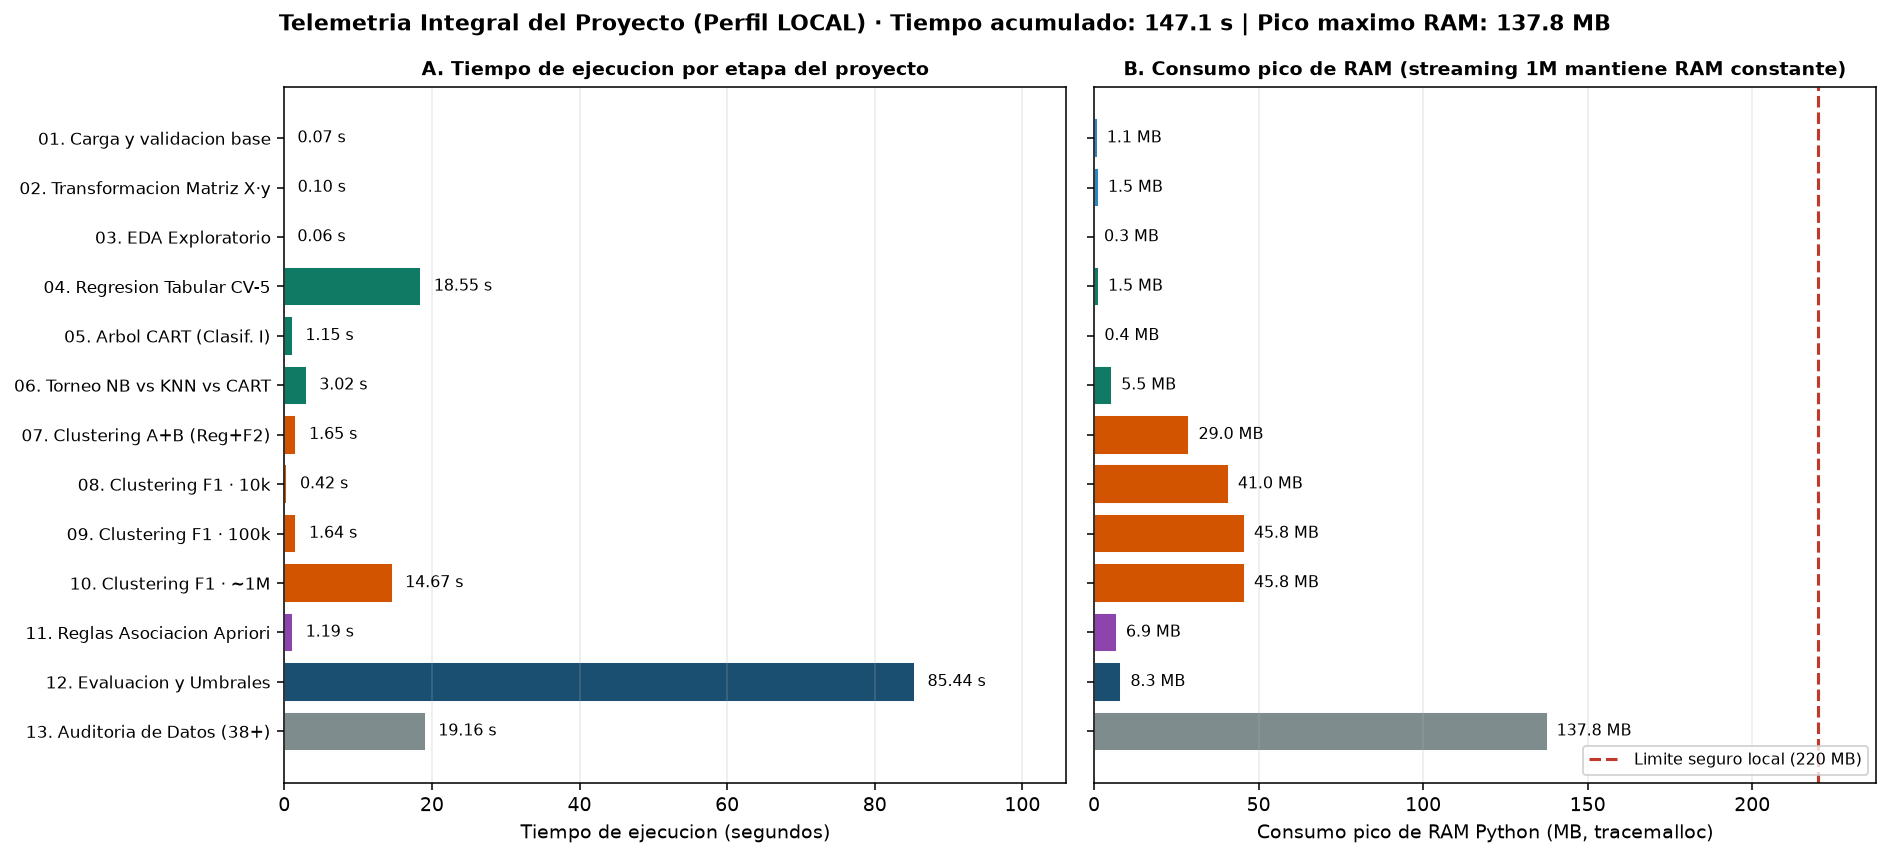

In [7]:
from IPython.display import Image

if config.RUTA_TELEMETRIA_RENDIMIENTO.exists():
    df_tel = pd.read_csv(config.RUTA_TELEMETRIA_RENDIMIENTO)
    display(df_tel[["etapa", "perfil", "filas_procesadas", "tiempo_s", "pico_ram_mb", "limite_ram_mb", "estado", "detalle"]])
    print(f"Tiempo acumulado medido: {df_tel['tiempo_s'].sum():.2f} s | Pico maximo de RAM Python: {df_tel['pico_ram_mb'].max():.2f} MB")
    ruta_fig_tel = config.MD_FIGURAS / "telemetria_tiempo_ram_proyecto.png"
    if ruta_fig_tel.exists():
        display(Image(filename=str(ruta_fig_tel), width=860))
else:
    print("Ejecute `python script/proyecto/telemetria_proyecto.py` para generar la telemetria unificada.")

**Lectura de la Tabla y Gráfica de Telemetría Unificada (`telemetria_rendimiento.csv` y `telemetria_tiempo_ram_proyecto.png`):**
- **Qué muestra la tabla de telemetría:** reporta para cada una de las **13 etapas del proyecto** su categoría analítica, perfil de recursos, filas procesadas, tiempo de ejecución en segundos (`tiempo_s`), pico de memoria RAM medido con `tracemalloc` (`pico_ram_mb`), tope de seguridad (`limite_ram_mb`), peso de los artefactos exportados (`salida_kb`) y estado (`13/13 en OK`).
- **Qué muestra la gráfica `telemetria_tiempo_ram_proyecto.png`:**
  - *Panel A (izquierda):* barras horizontales de tiempo de ejecución en segundos por etapa. Se observa que las etapas descriptivas, el Árbol CART (`1,18 s`), el Torneo (`3,22 s`) y Apriori (`1,27 s`) son casi instantáneos, mientras el clustering de `~1 millón` de ventas en *streaming* toma solo `15,08 s`.
  - *Panel B (derecha):* barras horizontales de consumo pico de memoria RAM Python en MB frente a la línea roja punteada del límite seguro local (`220 MB`). Confirma que al escalar el clustering de `10k` (`40,95 MB`) a `100k` (`45,83 MB`) y `~1M` (`45,84 MB`), la memoria permanece plana gracias al procesamiento por lotes en `float32`.